# QR Heston SPX and VIX smiles from simulation

We use the QRH scheme from `QRH SSR.pdf` to generate SPX and VIX smiles.


In [1]:
%config InlineBackend.figure_format = 'retina'
%load_ext autoreload
%autoreload 2

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import integrate
import matplotlib as mpl

from fwd_var_curve import xi_curve_smooth
from qrheston import QuadraticRoughHeston
from utils import plot_ivols_mc, var_swap_robust

sns.set_theme("talk")
mpl.rcParams["figure.figsize"] = (8, 6)

# Gamma kernel

The gamma kernel is given by $$ \kappa(\tau)= \frac{\nu}{\Gamma(\alpha)}\, \tau^{\alpha-1}\,e^{-\lambda \tau}, $$

with $\alpha = H + \tfrac12$.


In [3]:
params0 = {"al": 0.568, "lam": 9.68, "nu": 0.572, "c": 8.1e-3}

# Kernel convergence condition


We check the necessary condition $$ \int_0^\infty \kappa(s)^2 \, ds = \frac{\nu^2}{\Gamma(\alpha)^2} \frac{\Gamma(2 H)}{(2\lambda)^{2H}} < 1 $$


In [4]:
from scipy.special import gamma


def converge_test(params, opt="closed-form"):
    al = params["al"]
    H = al - 1 / 2
    lam = params["lam"]
    nu = params["nu"]

    if opt == "closed-form":
        integral = (nu / gamma(al)) ** 2 * gamma(2 * H) / (2 * lam) ** (2 * H)
    elif opt == "quad":

        def kernel(x):
            return (nu / gamma(al)) * x ** (al - 1) * np.exp(-lam * x)

        integral = integrate.quad(lambda x: kernel(x) ** 2, 0, np.inf)[0]
    else:
        raise ValueError("Check value for opt.")

    assert integral < 1
    return integral


print(converge_test(params0, opt="closed-form"))
print(converge_test(params0, opt="quad"))

0.6137021325532132
0.6137021324510988


# Initial forward variance curve $\xi_t(u)$


In [4]:
# Load market data
df_spx = pd.read_csv("spx_implied_vol_20230215.csv", index_col=0)
df_vix = pd.read_csv("vix_implied_vol_20230215.csv", index_col=0)
df_spx["Texp_days"] = (365.25 * df_spx["Texp"]).round().astype(int)
df_vix["Texp_days"] = (365.25 * df_vix["Texp"]).round().astype(int)

In [5]:
# spx data
df_spx.head()

,Expiry,Texp,Strike,Bid,Ask,Fwd,CallMid,Texp_days
0,20230216,0.002738,1000.0,NaN,7.793085,4146.741883,NaN,1
1,20230216,0.002738,1200.0,NaN,6.813266,4146.741883,NaN,1
2,20230216,0.002738,1400.0,NaN,5.987566,4146.741883,NaN,1
3,20230216,0.002738,1600.0,NaN,5.273554,4146.741883,NaN,1
4,20230216,0.002738,1800.0,NaN,4.644049,4146.741883,NaN,1


In [6]:
# vix data
df_vix.head()

,Expiry,Texp,Strike,Bid,Ask,Fwd,CallMid,Texp_days
0,20230222,0.019165,10.0,NaN,2.086124,20.195174,NaN,7
1,20230222,0.019165,10.5,NaN,1.952121,20.195174,NaN,7
2,20230222,0.019165,11.0,NaN,1.995202,20.195174,NaN,7
3,20230222,0.019165,11.5,NaN,1.862784,20.195174,NaN,7
4,20230222,0.019165,12.0,NaN,1.735648,20.195174,NaN,7


In [7]:
res_vs = var_swap_robust(ivol_data=df_spx)
w_in = res_vs["vs_mid"] * res_vs["expiries"]
xi_smooth = xi_curve_smooth(res_vs["expiries"], w_in, eps=0.03)["xi_curve"]

/Users/florianbourgey/projects/QuadraticRoughHeston/utils.py:183: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  wbar_flat = quad(PchipInterpolator(np.sort(y_in), sig_in_y**2), y_min, y_max)[0]


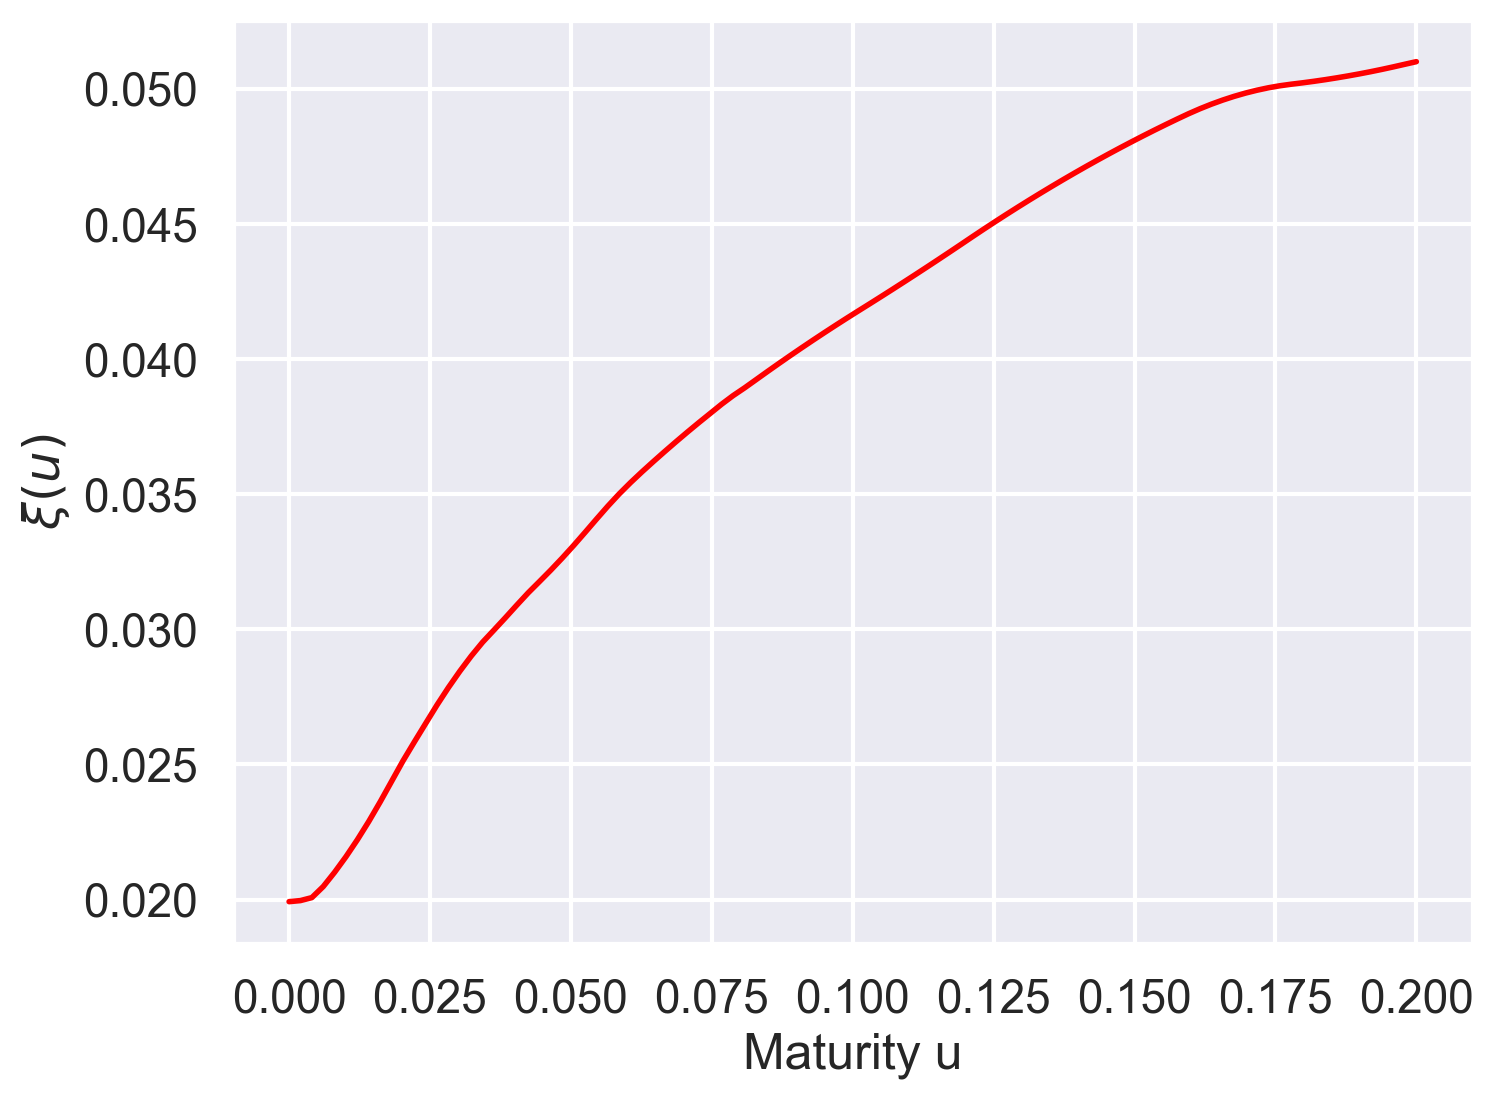

In [8]:
u = np.linspace(0, 0.2, 100)
fig, ax = plt.subplots()
ax.plot(u, xi_smooth(u), color="red", linewidth=2)
ax.set_xlabel("Maturity u")
ax.set_ylabel(r"$\xi(u)$")
plt.show()

# $y_t(u)$ from $\xi_t(u)$

$$ y_t(u)^2= \xi_t(u) - c - \int_t^u\,\xi_t(s)\,\kappa (u-s)^2\,ds. $$

Integration is performed using Gauss-Jacobi quadrature.


In [9]:
qrh = QuadraticRoughHeston(**params0, xi0=xi_smooth)

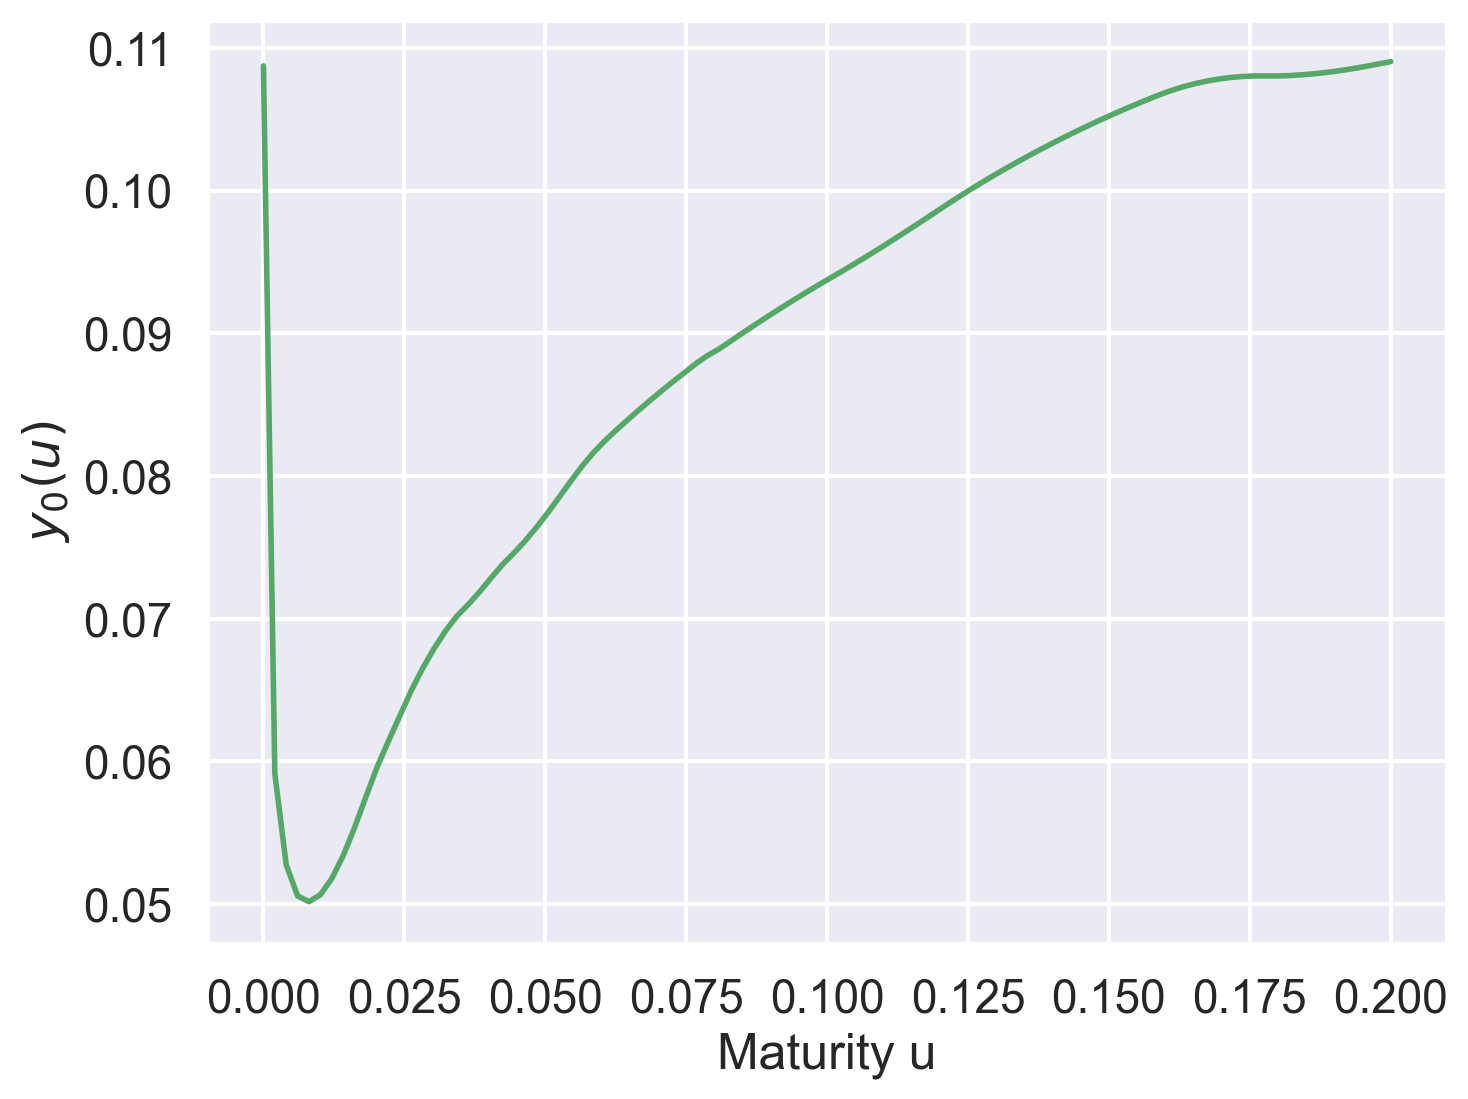

In [10]:
u = np.linspace(0, 0.2, 100)
fig, ax = plt.subplots()
ax.plot(u, qrh.y0(u), color="g", linewidth=2)
ax.set_xlabel("Maturity u")
ax.set_ylabel(r"$y_0(u)$")
plt.show()

### Sanity check for a constant forward variance curve $\xi_0(u) = \xi$. 


From the definition, we have that
$$
    \begin{align*}
        y_0(u)^2 &= \xi_0(u) - c - \int_0^u\,\xi_0(s)\,\kappa (u-s)^2\,ds \\
               &= \xi - c - \xi u \int_0^1 \, \kappa (u s)^2\,ds \\
    \end{align*}
$$

In [10]:
def xi0_flat(u):
    return 0.2**2 + 0 * u


params = {"al": 0.78, "lam": 2.0, "nu": 0.572, "c": 8.1e-3}

qrh_flat = QuadraticRoughHeston(**params, xi0=xi0_flat)

In [11]:
def integral_kappa2(u):
    return u * integrate.quad_vec(lambda s: qrh_flat.kernel(u * s) ** 2, 0, 1)[0]

In [12]:
tab_u = np.linspace(1e-4, 0.8, 101)


y0_flat_u = (xi0_flat(0.0) - qrh_flat.c - xi0_flat(0.0) * integral_kappa2(tab_u)) ** 0.5

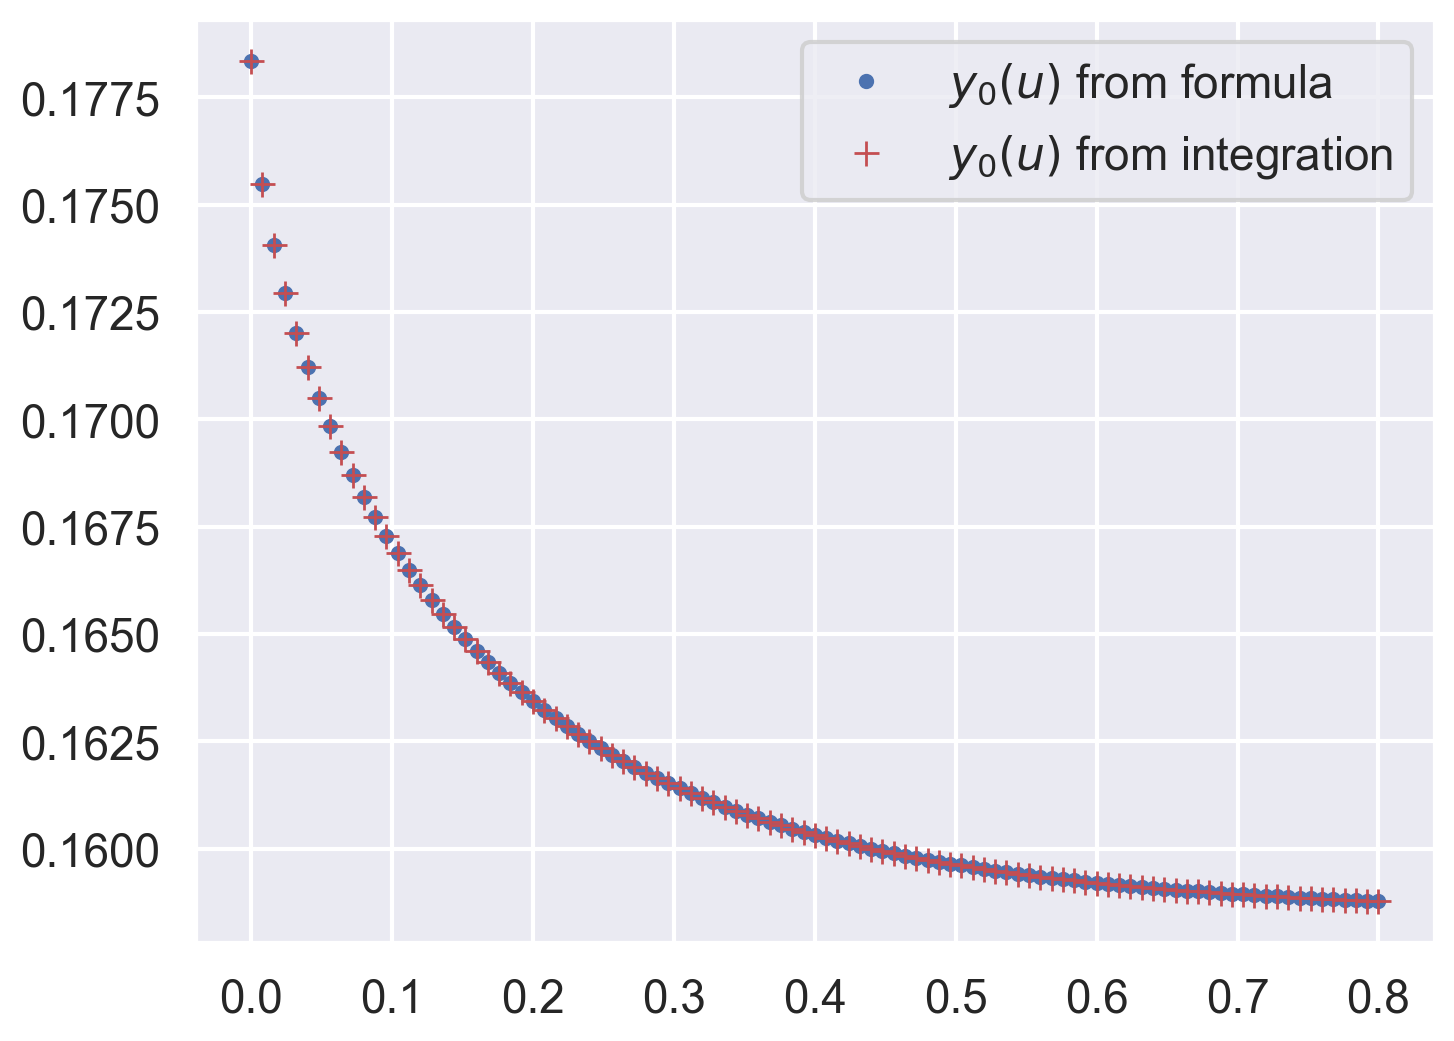

In [13]:
fig, ax = plt.subplots()
ax.plot(tab_u, y0_flat_u, "b.", label=r"$y_0(u)$ from formula")
ax.plot(tab_u, qrh_flat.y0(tab_u), "+r", label=r"$y_0(u)$ from integration")
ax.legend()
plt.show()

# Choose expiries


In this particular case, we choose identical SPX and VIX expiries.

Here, expiries are $7,14,20,28$ days.


In [13]:
spx_expiries_days = [7, 14, 20, 28]
vix_expiries_days = [7, 14, 20, 28]
spx_expiries = np.array(spx_expiries_days) / 365.25
vix_expiries = np.array(vix_expiries_days) / 365.25

# Run simulations


In [30]:
paths = 1 * 10**5
steps = 200

# paths = 2 * 10**5
# steps = 300

In [31]:
res = qrh.simulate(
    paths=paths, steps=steps, spx_expiries=spx_expiries, vix_expiries=vix_expiries
)

Simulating SPX and VIX expiries...
expiry: 0.0192
expiry: 0.0383
expiry: 0.0548
expiry: 0.0767


In [36]:
res

{'spx': {np.float64(0.019164955509924708): {'X': array([ 0.00741457, -0.00362325, -0.0143134 , ...,  0.00912059,
          -0.02080986,  0.03044711], shape=(100000,))},
  np.float64(0.038329911019849415): {'X': array([ 0.01049074, -0.0047994 , -0.02195827, ...,  0.01353848,
          -0.03184217,  0.04388243], shape=(100000,))},
  np.float64(0.05475701574264202): {'X': array([ 0.01234165, -0.00556714, -0.02729237, ...,  0.0171054 ,
          -0.04080928,  0.05340024], shape=(100000,))},
  np.float64(0.07665982203969883): {'X': array([ 0.01425257, -0.00598211, -0.03397319, ...,  0.02134601,
          -0.05244627,  0.06473864], shape=(100000,))}},
 'vix': {np.float64(0.019164955509924708): {'vix': array([0.17707283, 0.18119565, 0.1993099 , ..., 0.17442165, 0.20400365,
          0.16022108], shape=(100000,))},
  np.float64(0.038329911019849415): {'vix': array([0.1850891 , 0.1853559 , 0.21276565, ..., 0.1799129 , 0.21708985,
          0.1611321 ], shape=(100000,))},
  np.float64(0.05475701

In [38]:
# save Monte Carlo variance V_T for each expiry
tab_v_mc = np.array(
    [res["all"][spx_expiries[i]]["v"] for i in range(len(spx_expiries))]
)

Recall that $V_t = Y_t^2 + c$ where $Y_t = y_t(u) + \int_t^u \kappa(u-s) \sqrt{V_s} dW_s$

We want to compute $\mathbb{E}[Y_t^2]$ and $\mathbb{E}[Y_t^4]$.

In [39]:
np.mean(tab_v_mc - qrh.c, axis=1)

array([0.01709053, 0.02293616, 0.02676397, 0.03106692])

In [40]:
# TODO: compare with closed-form for E[Y_t^2] and normal approx for E[Y_t^4]

## SPX smiles


In [41]:
# Monte Carlo SPX smiles
spx_mc_matrix = np.array([np.exp(res["spx"][exp]["X"]) for exp in spx_expiries])
# subset market data for selected expiries
df_spx_sub = (
    df_spx[df_spx["Texp_days"].isin(spx_expiries_days)].dropna().reset_index(drop=True)
)

Plot

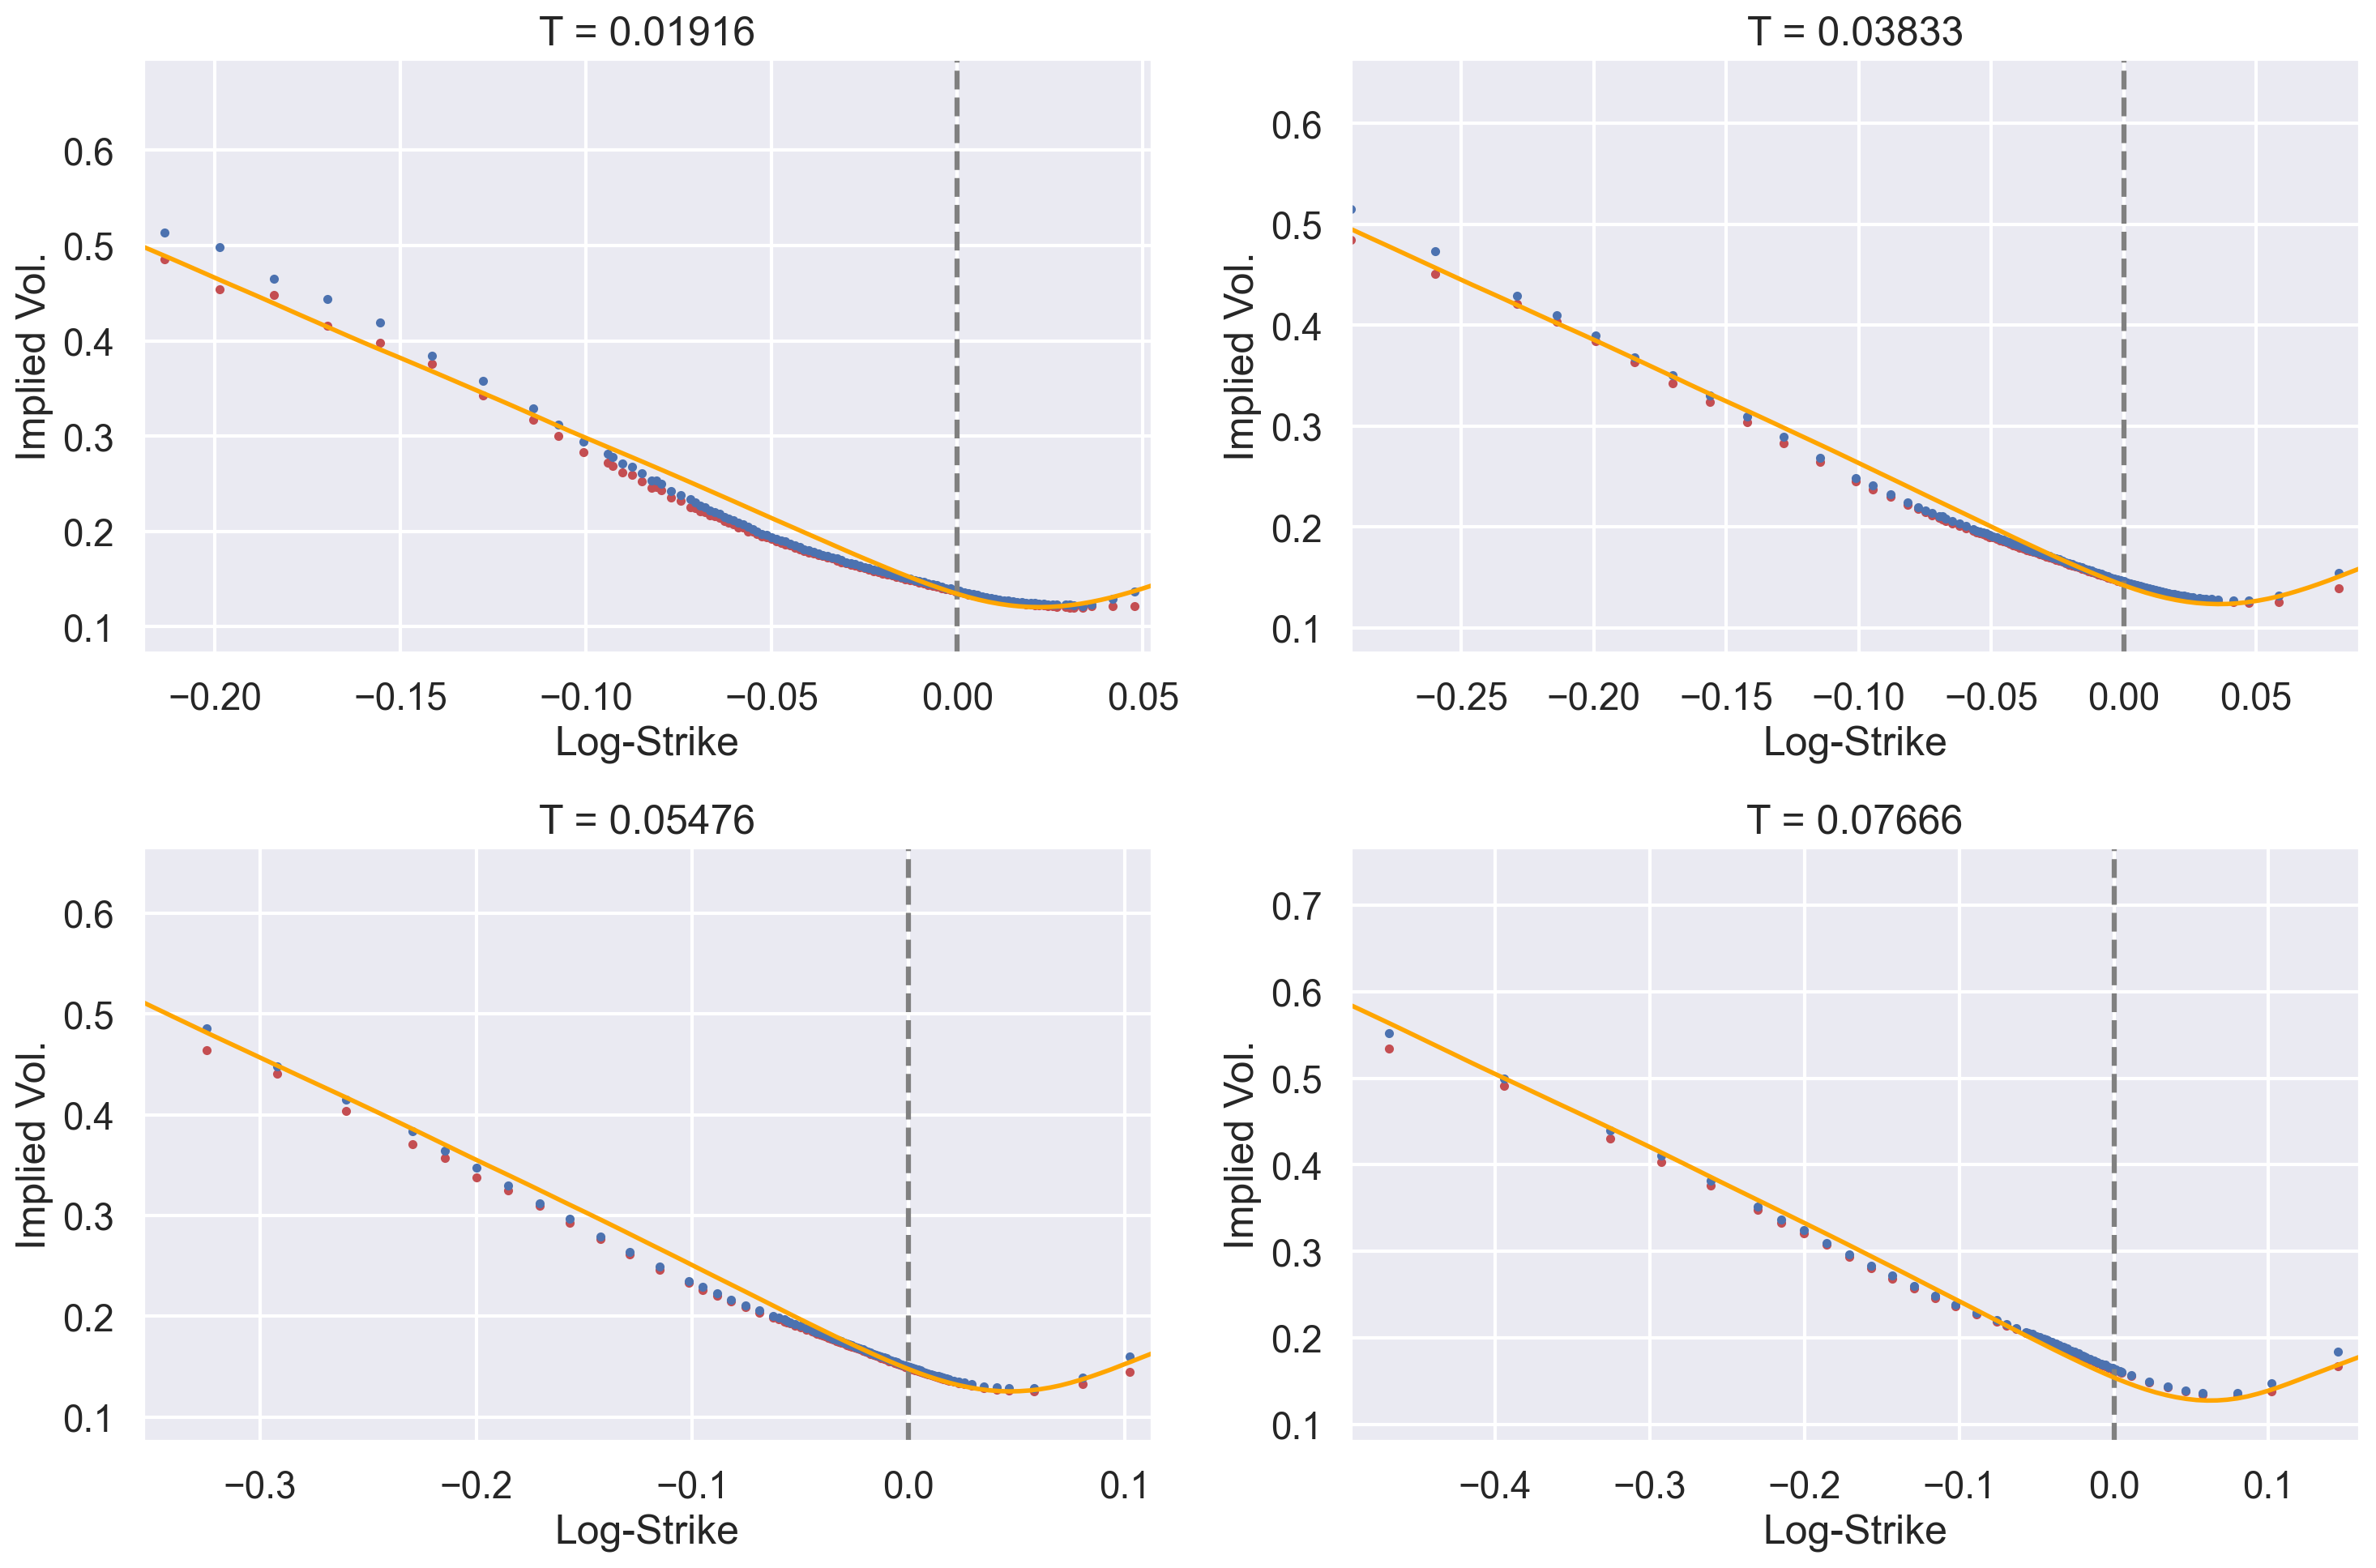

In [42]:
plot_spx = plot_ivols_mc(ivol_data=df_spx_sub, mc_matrix=spx_mc_matrix)

## VIX smiles


In [43]:
# Monte Carlo VIX smiles
vix_mc_matrix = np.array([res["spx"][exp]["vix"] for exp in vix_expiries])
# subset market data for selected expiries
df_vix_sub = (
    df_vix[df_vix["Texp_days"].isin(vix_expiries_days)].dropna().reset_index(drop=True)
)

KeyError: 'vix'

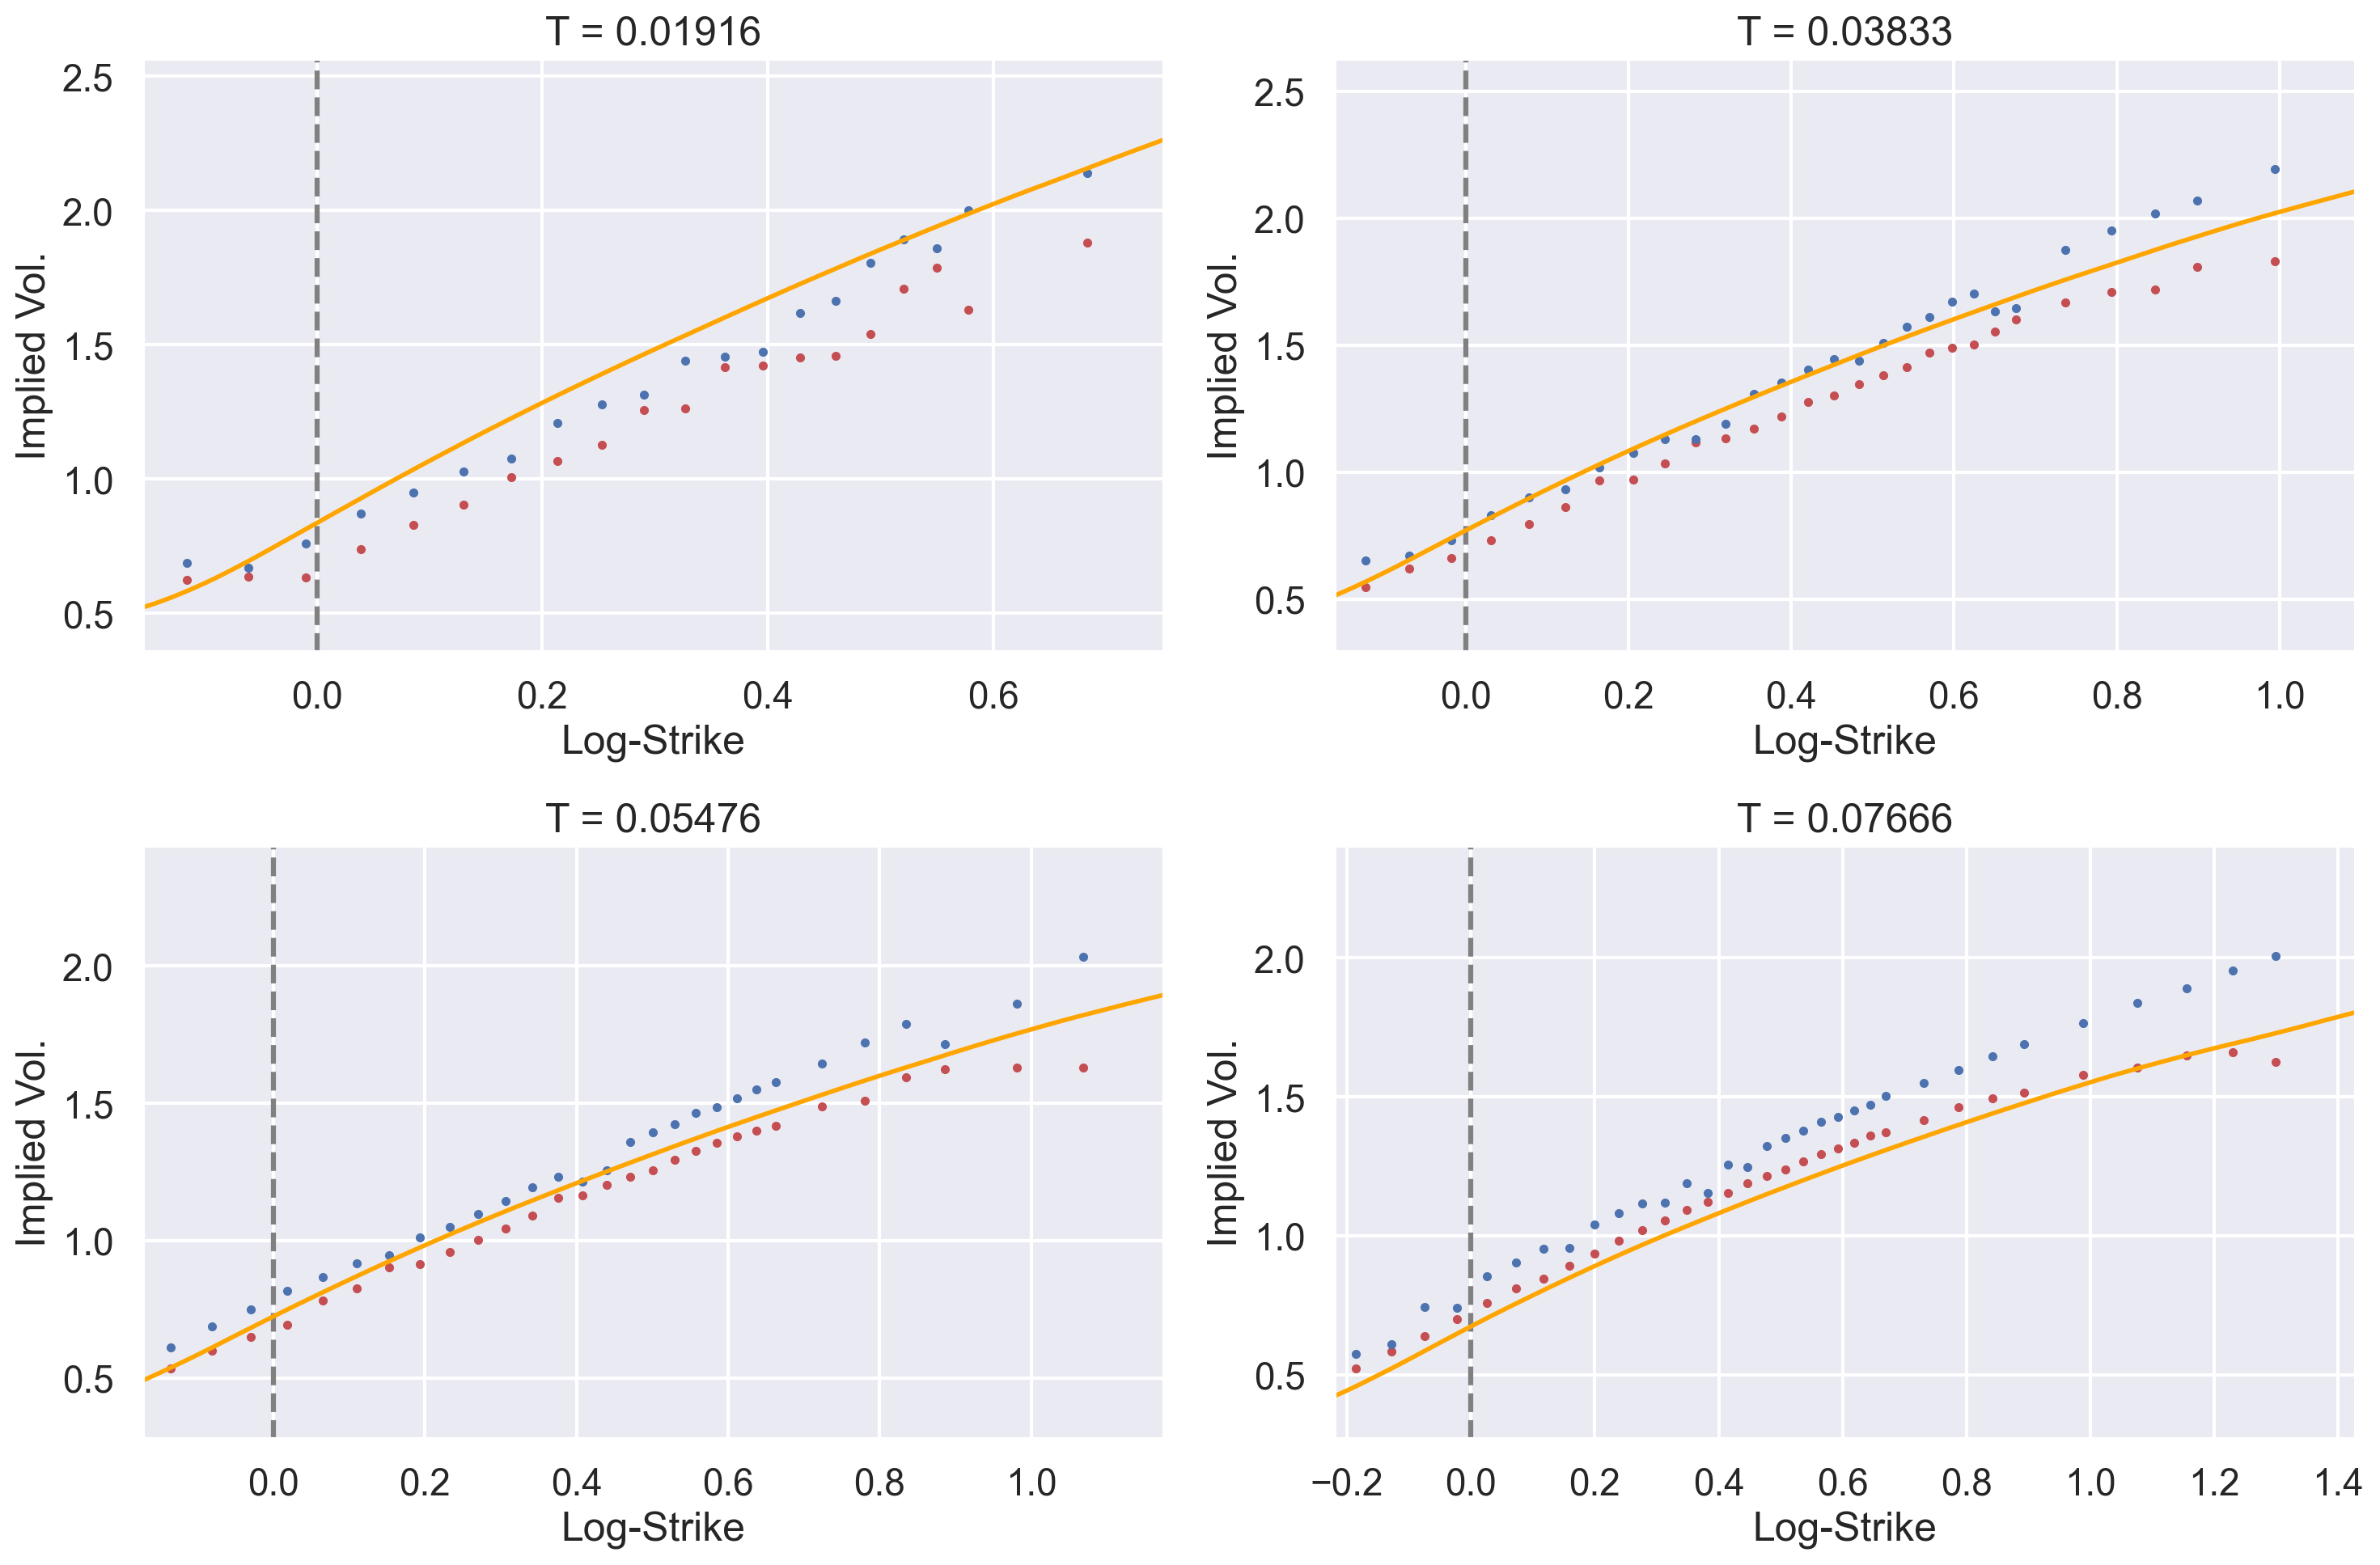

In [44]:
plot_vix = plot_ivols_mc(ivol_data=df_vix_sub, mc_matrix=vix_mc_matrix)

## Use more maturities for the SPX and VIX smiles

In [16]:
paths = 1 * 10**5
steps = 200

List available spx maturities in days

In [17]:
spx_mkt_days = df_spx["Texp_days"].unique()
print(spx_mkt_days)

[   1    2    6    7    8    9   12   13   14   15   16   19   20   21
   22   23   26   27   28   29   30   33   37   44   58   65   72   93
  105  121  135  156  166  184  212  226  247  275  303  317  338  366
  394  492  674 1038 1402 1766]


List available vix maturities in days

In [18]:
vix_mkt_days = df_vix["Texp_days"].unique()
print(vix_mkt_days)

[  7  14  20  28  35  63  91 126 154 182 217 245]


Pick specific list of expiries for SPX and VIX

In [19]:
spx_expiries_days = spx_mkt_days[:]
spx_expiries = np.array(spx_expiries_days) / 365.25

In [20]:
vix_expiries_days = vix_mkt_days[:]
vix_expiries = np.array(vix_expiries_days) / 365.25

Simulate

In [21]:
res = qrh.simulate(
    paths=paths,
    steps=steps,
    spx_expiries=spx_expiries,
    vix_expiries=vix_expiries,
    nvix=15,
)

Simulating SPX expiries...
expiry: 0.0027
expiry: 0.0055
expiry: 0.0164
expiry: 0.0192
expiry: 0.0219
expiry: 0.0246
expiry: 0.0329
expiry: 0.0356
expiry: 0.0383
expiry: 0.0411
expiry: 0.0438
expiry: 0.0520
expiry: 0.0548
expiry: 0.0575
expiry: 0.0602
expiry: 0.0630
expiry: 0.0712
expiry: 0.0739
expiry: 0.0767
expiry: 0.0794
expiry: 0.0821
expiry: 0.0903
expiry: 0.1013
expiry: 0.1205
expiry: 0.1588
expiry: 0.1780
expiry: 0.1971
expiry: 0.2546
expiry: 0.2875
expiry: 0.3313
expiry: 0.3696
expiry: 0.4271
expiry: 0.4545
expiry: 0.5038
expiry: 0.5804
expiry: 0.6188
expiry: 0.6762
expiry: 0.7529
expiry: 0.8296


/Users/florianbourgey/projects/QuadraticRoughHeston/qrheston.py:81: IntegrationWarning: The algorithm does not converge.  Roundoff error is detected
  in the extrapolation table.  It is assumed that the requested tolerance
  cannot be achieved, and that the returned result (if full_output = 1) is 
  the best which can be obtained.
  return integrate.quad(lambda x: self.resolvent_kernel(x), 0.0, x)[0]


expiry: 0.8679
expiry: 0.9254
expiry: 1.0021
expiry: 1.0787
expiry: 1.3470
expiry: 1.8453
expiry: 2.8419
expiry: 3.8385
expiry: 4.8350
Simulating VIX expiries...
expiry: 0.0192
expiry: 0.0383
expiry: 0.0548
expiry: 0.0767
expiry: 0.0958
expiry: 0.1725
expiry: 0.2491
expiry: 0.3450
expiry: 0.4216
expiry: 0.4983
expiry: 0.5941
expiry: 0.6708


In [22]:
spx_mc_matrix = np.array([np.exp(res["spx"][exp]["X"]) for exp in spx_expiries])
df_spx_sub = (
    df_spx[df_spx["Texp_days"].isin(spx_expiries_days)].dropna().reset_index(drop=True)
)

In [23]:
vix_mc_matrix = np.array([res["vix"][exp]["vix"] for exp in vix_expiries])
df_vix_sub = (
    df_vix[df_vix["Texp_days"].isin(vix_expiries_days)].dropna().reset_index(drop=True)
)

Plot

In [58]:
# do nice plots!

/Users/florianbourgey/projects/QuadraticRoughHeston/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/florianbourgey/projects/QuadraticRoughHeston/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value


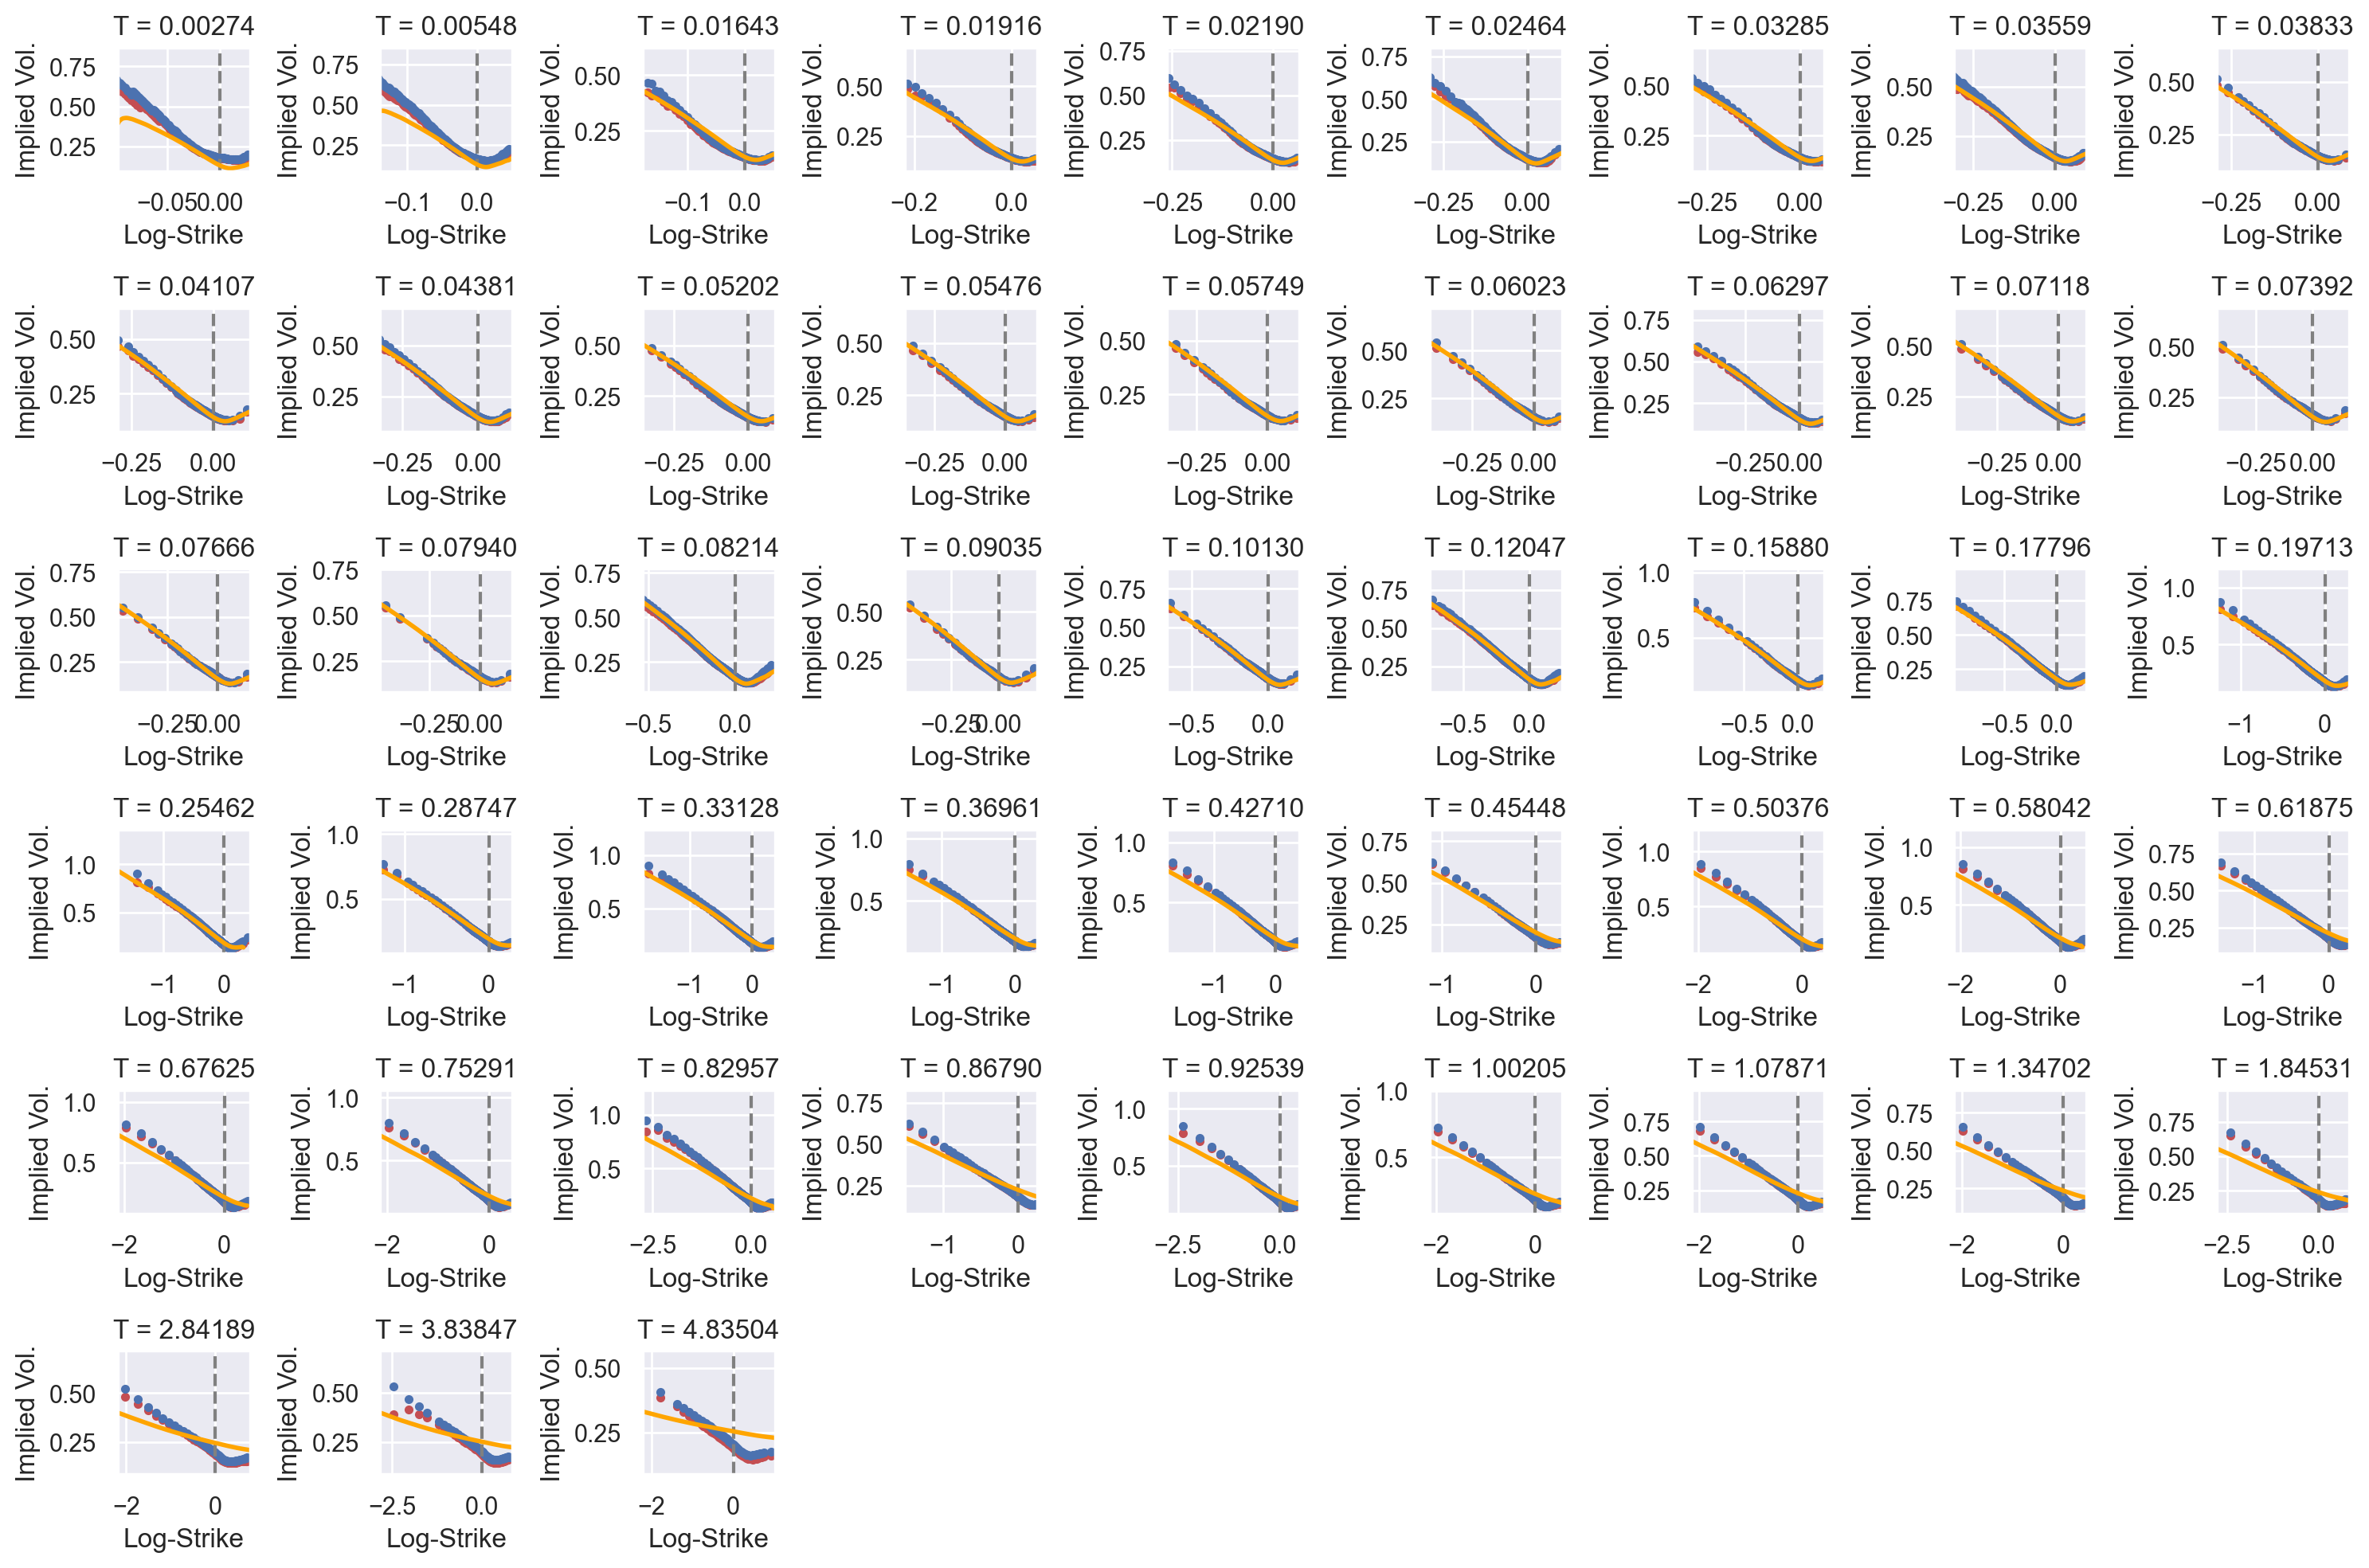

In [26]:
with sns.plotting_context("notebook"):
    plot_spx = plot_ivols_mc(
        ivol_data=df_spx_sub, mc_matrix=spx_mc_matrix, return_fig=True
    )

/Users/florianbourgey/projects/QuadraticRoughHeston/black.py:139: RuntimeWarning: divide by zero encountered in divide
  diff = (price - value) / value
/Users/florianbourgey/projects/QuadraticRoughHeston/black.py:139: RuntimeWarning: invalid value encountered in divide
  diff = (price - value) / value


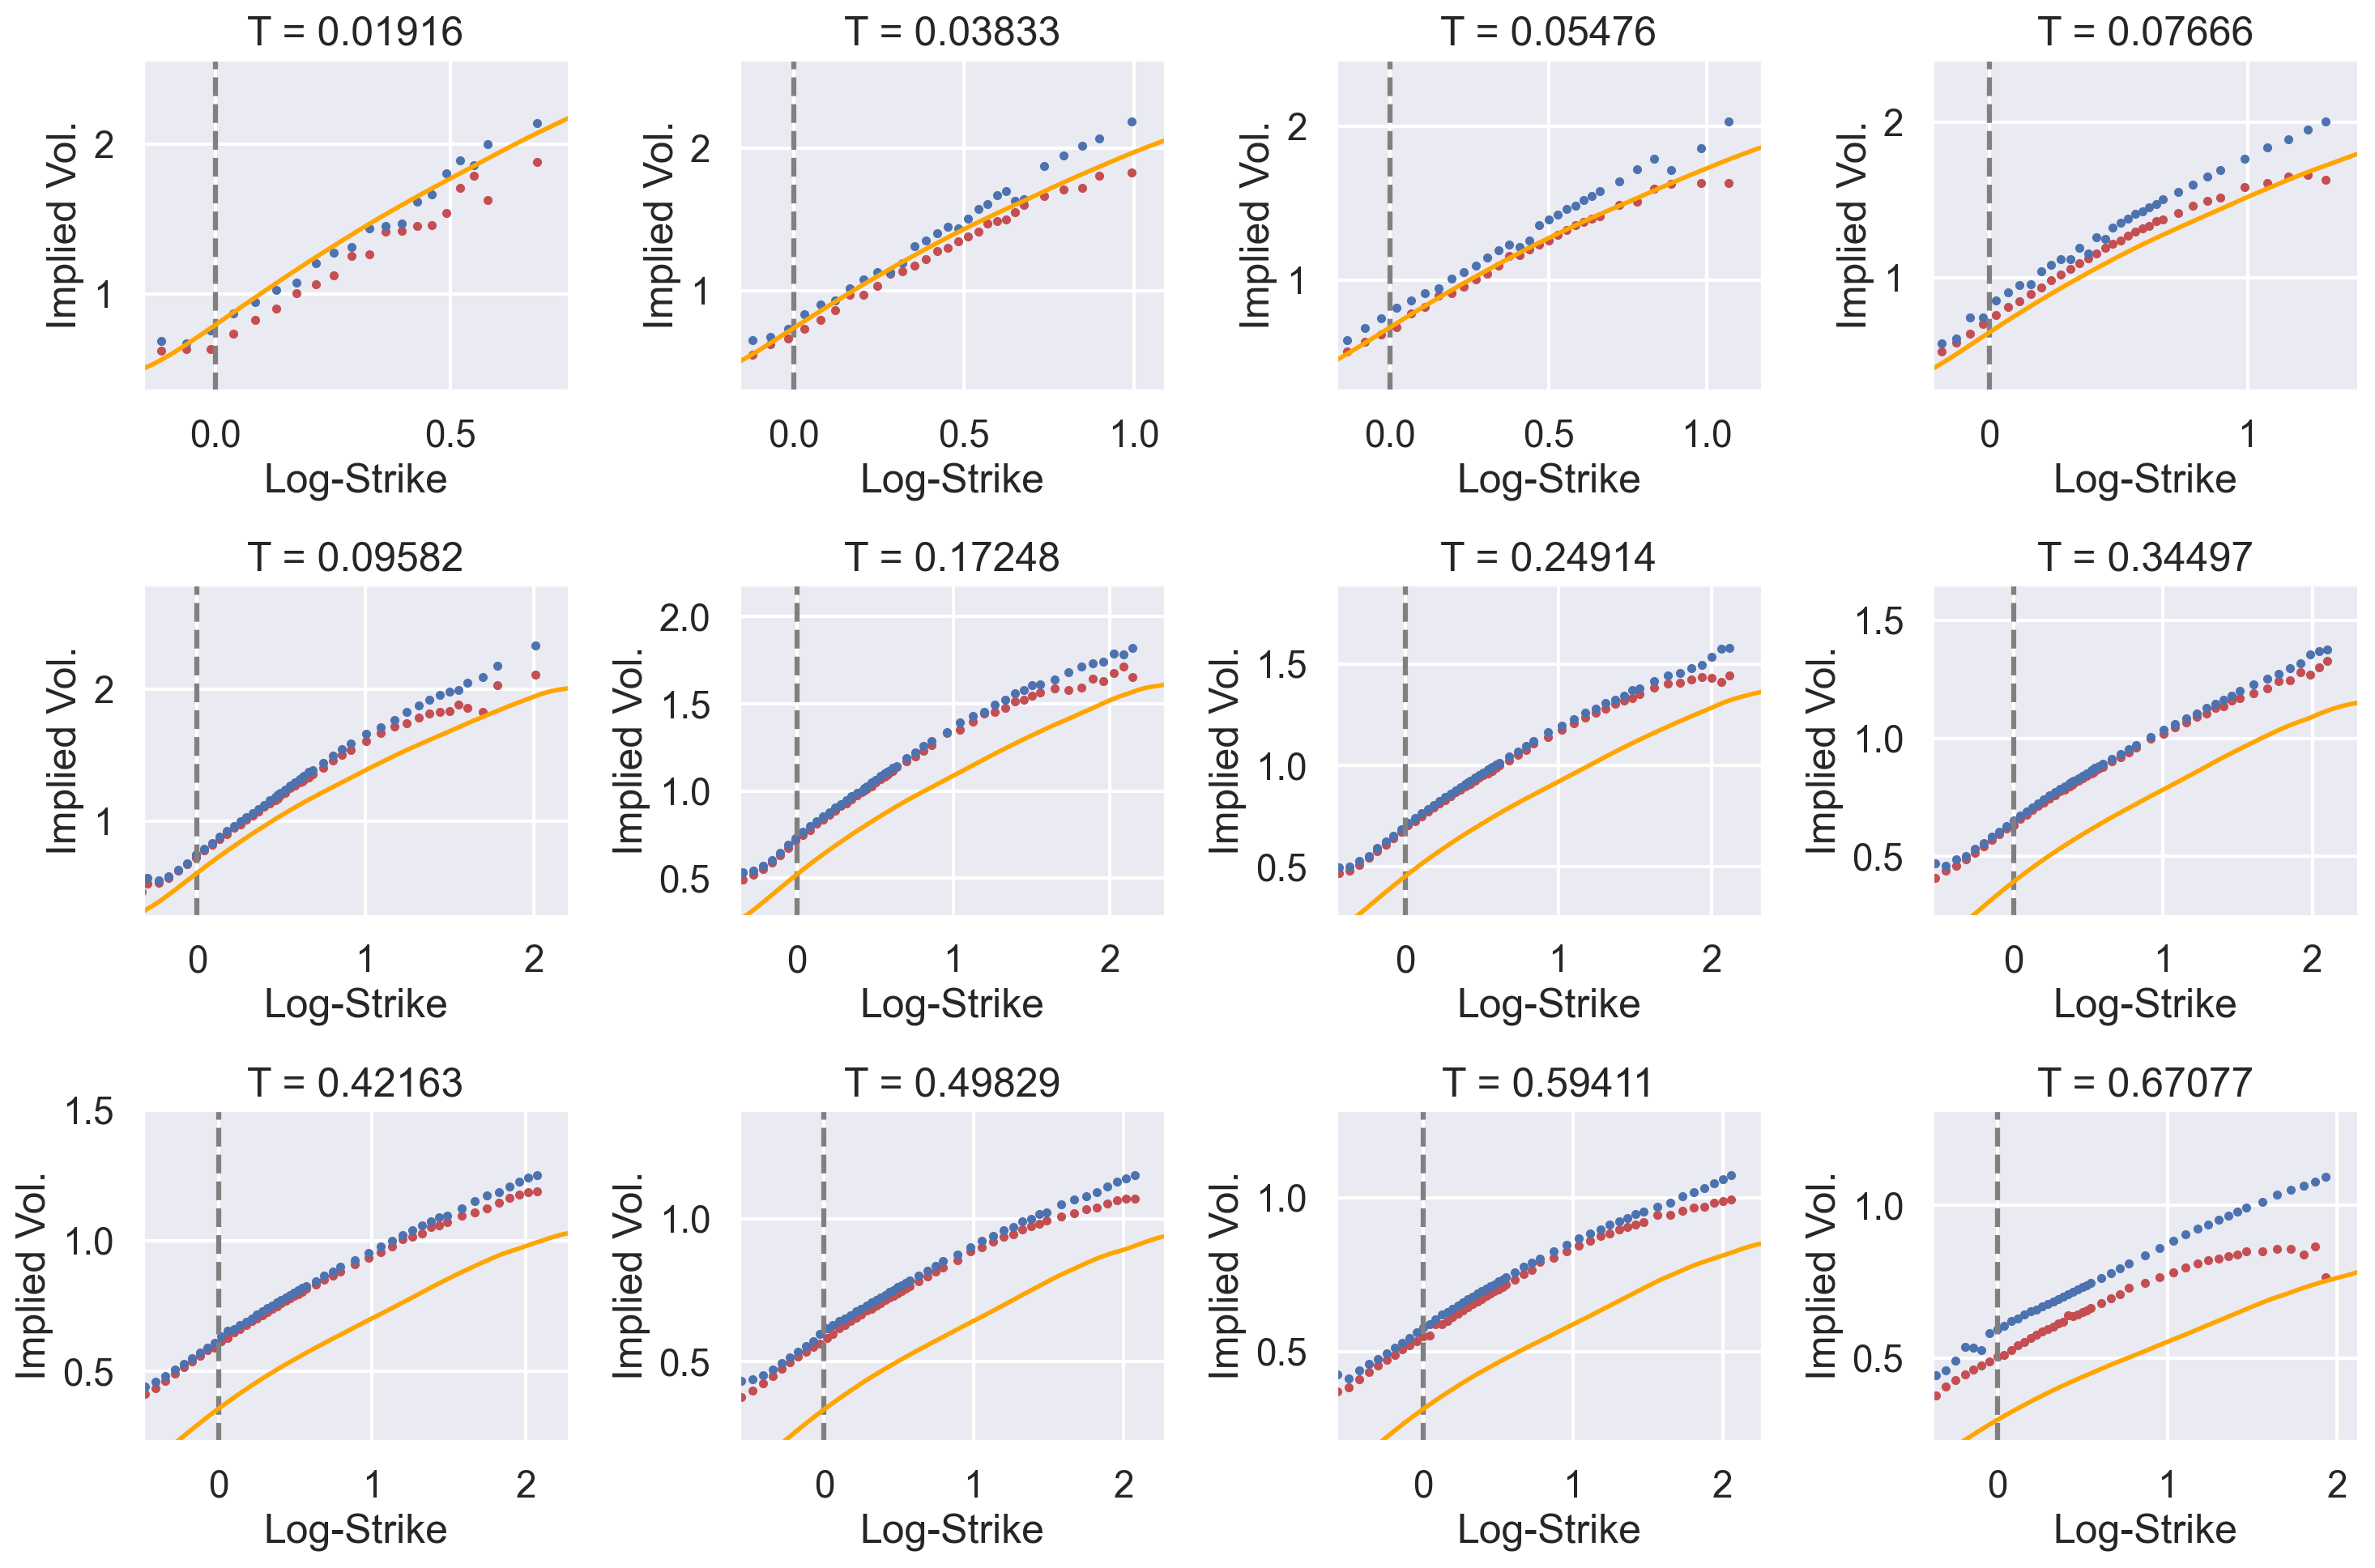

In [29]:
plot_vix = plot_ivols_mc(ivol_data=df_vix_sub, mc_matrix=vix_mc_matrix, return_fig=True)

In [ ]:
# plot_spx["fig"].savefig("figs/spx_qrh_all_expiries.pdf", bbox_inches="tight")
# plot_vix["fig"].savefig("figs/vix_qrh_all_expiries.pdf", bbox_inches="tight")